# ДЗ №2. Прогнозирование продаж: построение и оценка моделей временных рядов

Выполнил студент 1 курса магистратуры ИПИИ Кожемякин Григорий

Используются подготовленные в ДЗ №1 ряды продаж товара 22384 — LUNCH BAG PINK POLKADOT на дневной, недельной и месячной частотах. 
Полезные для работы функции, реализованные в первом домашнем задании, переиспользованы и приведены в ячейках ниже.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

PRODUCT_CODE = "22384"
DATA_PATH = Path("Online Retail.xlsx")

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

In [2]:
def load_data(path):
    df = pd.read_excel(
        path,
        dtype={"StockCode": "string", "InvoiceNo": "string"},
    )
    df["InvoiceDate"] = pd.to_datetime(
        df["InvoiceDate"], errors="coerce"
    )
    return df


def build_sales_series(product, start_date, end_date):
    cancelled = (
        product["InvoiceNo"]
        .str.upper()
        .str.startswith("C", na=False)
    )

    mask = (
        product["Quantity"].gt(0)
        & product["UnitPrice"].gt(0)
        & ~cancelled
    )

    sales = product.loc[mask].copy()

    calendar = pd.date_range(
        start=start_date.normalize(),
        end=end_date.normalize(),
        freq="D",
        name="InvoiceDate",
    )

    daily = (
        sales.set_index("InvoiceDate")["Quantity"]
        .resample("D")
        .sum()
        .reindex(calendar, fill_value=0)
        .rename("units")
    )

    weekly = daily.resample("W-SUN").sum()
    monthly = daily.resample("MS").sum()

    return {
        "daily": daily,
        "weekly": weekly,
        "monthly": monthly,
    }


def select_complete_periods(series, start_date, end_date):
    start = start_date.normalize()
    end = end_date.normalize()

    daily = series["daily"]
    weekly = series["weekly"]
    monthly = series["monthly"]

    daily = daily.loc[
        (daily.index >= start) & (daily.index < end)
    ]

    weekly = weekly.loc[
        ((weekly.index - pd.Timedelta(days=6)) >= start)
        & (weekly.index < end)
    ]

    month_ends = monthly.index + pd.offsets.MonthEnd(0)

    monthly = monthly.loc[
        (monthly.index >= start) & (month_ends < end)
    ]

    return {
        "daily": daily,
        "weekly": weekly,
        "monthly": monthly,
    }

In [3]:
df = load_data(DATA_PATH)

product = df.loc[
    df["StockCode"].eq(PRODUCT_CODE)
].copy()

series = build_sales_series(
    product,
    start_date=df["InvoiceDate"].min(),
    end_date=df["InvoiceDate"].max(),
)

analysis_series = select_complete_periods(
    series,
    start_date=df["InvoiceDate"].min(),
    end_date=df["InvoiceDate"].max(),
)

In [4]:
def check_forecasting_data(series):
    rows = []

    for name, ts in series.items():
        expected_index = pd.date_range(
            start=ts.index.min(),
            end=ts.index.max(),
            freq=ts.index.freq,
        )

        rows.append({
            "frequency": name,
            "n": len(ts),
            "start": ts.index.min(),
            "end": ts.index.max(),
            "index_frequency": ts.index.freqstr,
            "regular": ts.index.equals(expected_index),
            "sorted": ts.index.is_monotonic_increasing,
            "duplicate_dates": ts.index.duplicated().sum(),
            "missing": ts.isna().sum(),
            "negative": ts.lt(0).sum(),
        })

    return pd.DataFrame(rows).set_index("frequency")


display(check_forecasting_data(analysis_series))

,n,start,end,index_frequency,regular,sorted,duplicate_dates,missing,negative
frequency,,,,,,,,,
daily,373,2010-12-01,2011-12-08,D,True,True,0,0,0
weekly,52,2010-12-12,2011-12-04,W-SUN,True,True,0,0,0
monthly,12,2010-12-01,2011-11-01,MS,True,True,0,0,0


## Схема оценки прогнозов

Используются три последовательные точки начала прогноза с расширяющейся обучающей выборкой. В каждой точке модели получают одинаковую историю и формируют прогноз на максимальный горизонт без доступа к будущим фактическим продажам.

Для горизонта h качество оценивается по первым h значениям прогнозной траектории. Рассматриваются:

- дневные горизонты 1, 7, 31, 61
- недельные — 1, 4, 8
- месячные — 1, 2.

Тестовые интервалы разных точек частично пересекаются, поэтому ошибки не являются независимыми. Месячные результаты имеют исследовательский
характер из-за малого числа наблюдений.

Схема фиксируется до сравнения качества моделей.

In [5]:
HORIZONS = {
    "daily": [1, 7, 31, 61],
    "weekly": [1, 4, 8],
    "monthly": [1, 2],
}

ORIGIN_STEPS = {
    "daily": 14,
    "weekly": 4,
    "monthly": 1,
}


def make_backtest_splits(series, horizons, origin_steps, n_origins=3):
    splits = {}
    rows = []

    for frequency, ts in series.items():
        max_horizon = max(horizons[frequency])
        step = origin_steps[frequency]

        last_train_size = len(ts) - max_horizon
        first_train_size = last_train_size - step * (n_origins - 1)

        if first_train_size < 2:
            raise ValueError(
                f"Недостаточно истории для {frequency}"
            )

        frequency_splits = []

        for fold in range(n_origins):
            train_size = first_train_size + fold * step

            train = ts.iloc[:train_size].copy()
            test = ts.iloc[
                train_size:train_size + max_horizon
            ].copy()

            frequency_splits.append({
                "fold": fold + 1,
                "train": train,
                "test": test,
            })

            rows.append({
                "frequency": frequency,
                "fold": fold + 1,
                "train_n": len(train),
                "train_end": train.index[-1],
                "test_start": test.index[0],
                "test_end": test.index[-1],
                "test_n": len(test),
            })

        splits[frequency] = frequency_splits

    summary = pd.DataFrame(rows)
    return splits, summary


splits, split_summary = make_backtest_splits(
    analysis_series,
    HORIZONS,
    ORIGIN_STEPS,
)

display(split_summary)

,frequency,fold,train_n,train_end,test_start,test_end,test_n
0,daily,1,284,2011-09-10,2011-09-11,2011-11-10,61
1,daily,2,298,2011-09-24,2011-09-25,2011-11-24,61
2,daily,3,312,2011-10-08,2011-10-09,2011-12-08,61
3,weekly,1,36,2011-08-14,2011-08-21,2011-10-09,8
4,weekly,2,40,2011-09-11,2011-09-18,2011-11-06,8
5,weekly,3,44,2011-10-09,2011-10-16,2011-12-04,8
6,monthly,1,8,2011-07-01,2011-08-01,2011-09-01,2
7,monthly,2,9,2011-08-01,2011-09-01,2011-10-01,2
8,monthly,3,10,2011-09-01,2011-10-01,2011-11-01,2


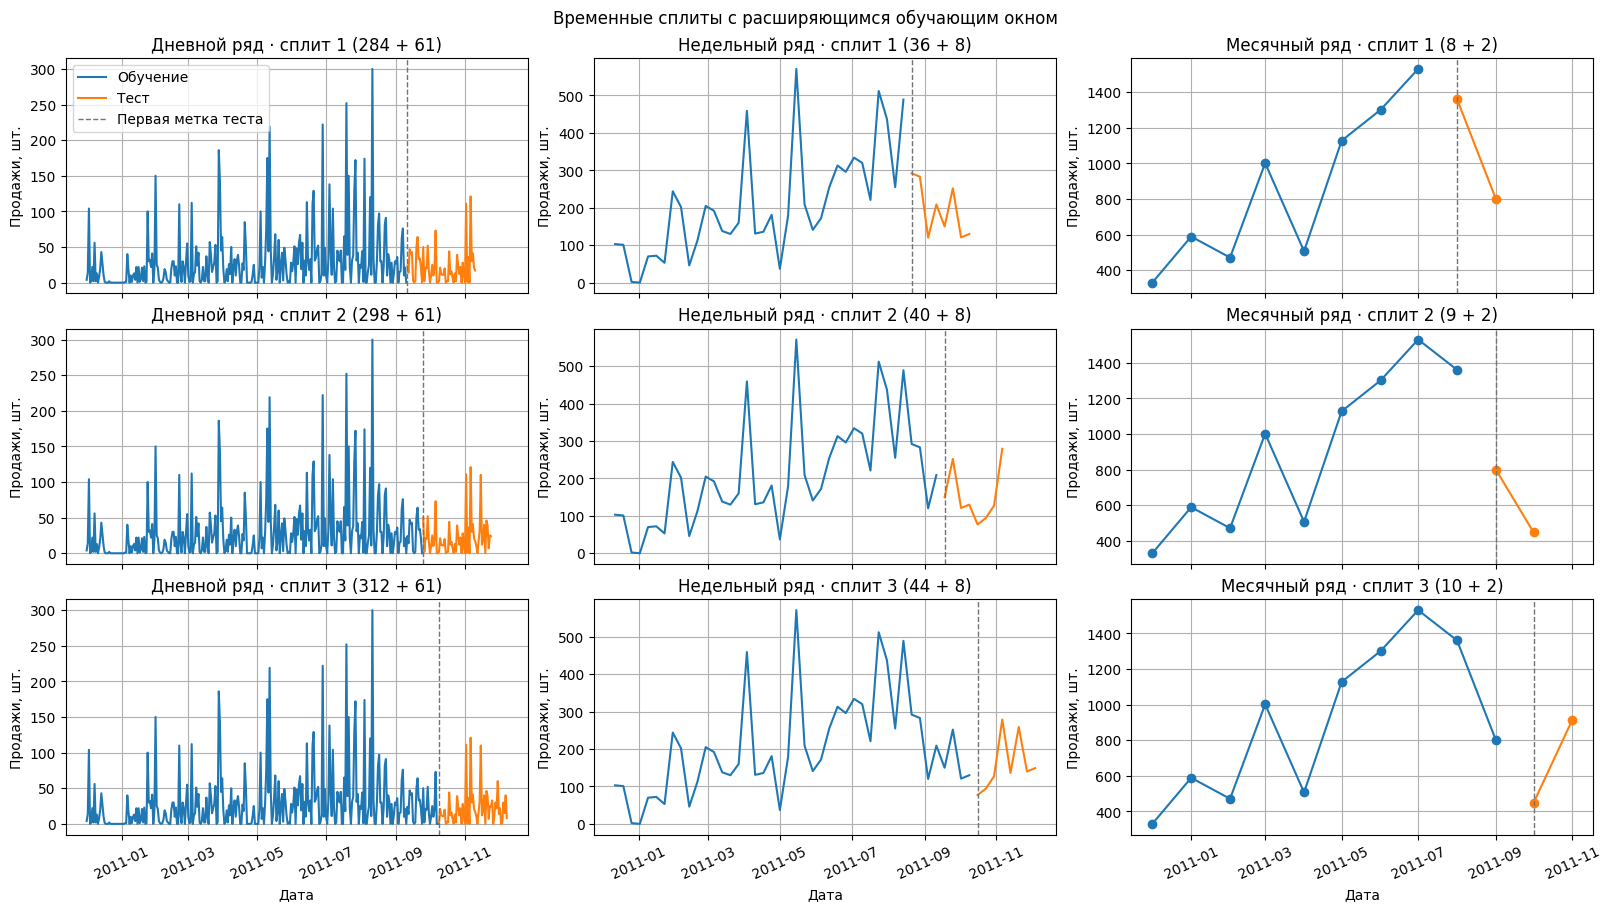

In [6]:
def plot_backtest_splits(splits):
    titles = {
        "daily": "Дневной ряд",
        "weekly": "Недельный ряд",
        "monthly": "Месячный ряд",
    }

    fig, axes = plt.subplots(
        3, 3,
        figsize=(16, 9),
        sharex="col",
        sharey="col",
        layout="constrained",
    )

    for col, (frequency, title) in enumerate(titles.items()):
        marker = "o" if frequency == "monthly" else None

        for row, split in enumerate(splits[frequency]):
            ax = axes[row, col]
            train = split["train"]
            test = split["test"]

            ax.plot(train.index, train, color="tab:blue",
                    marker=marker, label="Обучение")
            ax.plot(test.index, test, color="tab:orange",
                    marker=marker, label="Тест")
            ax.axvline(test.index[0], color="0.45", linestyle="--",
                       linewidth=1, label="Первая метка теста")

            ax.set_title(
                f"{title} · сплит {split['fold']} "
                f"({len(train)} + {len(test)})"
            )
            ax.set_ylabel("Продажи, шт.")
            ax.tick_params(axis="x", labelrotation=25)

        axes[-1, col].set_xlabel("Дата")

    axes[0, 0].legend()
    fig.suptitle("Временные сплиты с расширяющимся обучающим окном")
    plt.show()


plot_backtest_splits(splits)

## Наивный прогноз и метрики

На дневной частоте наивный прогноз повторяет последние семь наблюдений. На недельной и месячной частотах прогноз равен последнему наблюдению обучающей выборки.

Качество оценивается по MAE и MASE. 
MAE выбрана основной метрикой: для оценки обычной ошибки прогноза важно, чтобы редкие промахи на крупных заказах не получали повышенный вес, как в RMSE. MASE дополняет MAE при сравнении частот: она нормирует ошибку на типичный перепад продаж в обучающей истории. MAPE не определена при нулевых продажах, а знаменатель WAPE зависит от объёма продаж в тестовом окне и на коротких горизонтах может оказаться очень малым или нулевым.

Масштаб для MASE вычисляется отдельно в каждом сплите на обучающей истории: используется средняя абсолютная разность с лагом 7 для дневного ряда и с лагом 1 для недельного и месячного рядов.

Для горизонта h в оценку входят первые h ошибок каждого из трёх сплитов. Таким образом, в каждой строке таблицы усредняются 3 × h прогнозных ошибок, часть которых может относиться к одной и той же дате.

In [7]:
NAIVE_LAGS = {"daily": 7, "weekly": 1, "monthly": 1}


def naive_forecast(train, steps, frequency):
    lag = NAIVE_LAGS[frequency]
    pattern = train.iloc[-lag:].to_numpy(dtype=float)

    # Индексы идут по кругу, например 0, 1, ..., 6, 0, 1, ...
    return pattern[np.arange(steps) % lag]


def evaluate_model(model_name, forecast_fn, splits, horizons):
    rows = []

    for frequency, folds in splits.items():
        lag = NAIVE_LAGS[frequency]

        for split in folds:
            train = split["train"]
            test = split["test"]

            prediction = np.asarray(
                forecast_fn(train, len(test), frequency), dtype=float
            )
            if prediction.shape != (len(test),) or not np.isfinite(prediction).all():
                raise ValueError(f"Некорректный прогноз: {model_name}, {frequency}")

            absolute_error = np.abs(test.to_numpy(dtype=float) - prediction)
            scale = train.diff(lag).abs().mean()

            for h in horizons[frequency]:
                mae = absolute_error[:h].mean()
                rows.append({
                    "model": model_name,
                    "frequency": frequency,
                    "fold": split["fold"],
                    "horizon": h,
                    "MAE": mae,
                    "MASE": mae / scale if scale > 0 else np.nan,
                })

    return pd.DataFrame(rows)


naive_scores = evaluate_model("Naive", naive_forecast, splits, HORIZONS)

display(
    naive_scores.groupby(
        ["model", "frequency", "horizon"], sort=False
    )[["MAE", "MASE"]]
    .mean()
    .round(2)
)

MAE  MASE
model frequency horizon              
Naive daily     1         21.67  0.68
                7         18.67  0.59
                31        22.96  0.72
                61        22.88  0.72
      weekly    1        103.00  0.96
                4        130.17  1.22
                8        142.83  1.33
      monthly   1        361.00  1.07
                2        473.83  1.41

## Экспоненциальное сглаживание

Для дневного ряда используется экспоненциальное сглаживание с аддитивной недельной сезонностью (период 7) без компоненты тренда. Для недельного и месячного рядов оценивается только уровень. Параметры подбираются отдельно на обучающей части каждого сплита.

В каждом сплите модель обучается один раз и строит прогноз на максимальный горизонт. Для горизонта h метрики рассчитываются по первым h прогнозным значениям. Отрицательные прогнозы ограничиваются нулём, поскольку объём продаж неотрицателен.

In [8]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def exp_smoothing_forecast(train, steps, frequency):
    daily = frequency == "daily"

    model = ExponentialSmoothing(
        train.astype(float),
        trend=None,
        seasonal="add" if daily else None,
        seasonal_periods=7 if daily else None,
        initialization_method="estimated",
    )
    fitted = model.fit()

    prediction = np.asarray(fitted.forecast(steps), dtype=float)
    return np.maximum(prediction, 0.0)


smoothing_scores = evaluate_model(
    "ExpSmoothing", exp_smoothing_forecast, splits, HORIZONS
)

scores_so_far = pd.concat(
    [naive_scores, smoothing_scores], ignore_index=True
)

display(
    scores_so_far.groupby(
        ["frequency", "horizon", "model"], sort=False
    )[["MAE", "MASE"]]
    .mean()
    .unstack("model")
    .round(2)
)

MAE               MASE             
model               Naive ExpSmoothing Naive ExpSmoothing
frequency horizon                                        
daily     1         21.67        15.12  0.68         0.48
          7         18.67        16.98  0.59         0.53
          31        22.96        20.56  0.72         0.65
          61        22.88        22.24  0.72         0.70
weekly    1        103.00       102.09  0.96         0.96
          4        130.17       112.24  1.22         1.05
          8        142.83       120.35  1.33         1.12
monthly   1        361.00       404.50  1.07         1.20
          2        473.83       478.66  1.41         1.43

## CatBoost с лаговыми признаками

Для дневного ряда используются лаги 1, 2 и 7 и день недели прогнозируемой даты. Для недельного ряда используются лаги 1 и 2, для месячного — только лаг 1 из-за короткой обучающей истории.

В каждом сплите CatBoost обучается прогнозировать следующий период. Многошаговый прогноз строится рекурсивно: каждое предсказание добавляется к истории и может использоваться в лагах следующих шагов. Фактические тестовые продажи используются при расчёте метрик.

Гиперпараметры фиксируются до оценки качества. Для месячной модели используются деревья глубины 1: в её обучающих выборках после построения лага остаётся всего 7–9 примеров.

In [9]:
from catboost import CatBoostRegressor

CATBOOST_LAGS = {
    "daily": (1, 2, 7),
    "weekly": (1, 2),
    "monthly": (1,),
}


def make_catboost_train(train, frequency):
    features = pd.DataFrame(index=train.index)

    for lag in CATBOOST_LAGS[frequency]:
        features[f"lag_{lag}"] = train.shift(lag)

    if frequency == "daily":
        features["day_of_week"] = features.index.dayofweek

    # В начале ряда ещё нет полной истории для всех лагов.
    features = features.dropna()
    target = train.loc[features.index]

    return features, target


def catboost_forecast(train, steps, frequency):
    features, target = make_catboost_train(train, frequency)

    model = CatBoostRegressor(
        iterations=100,
        depth=1 if frequency == "monthly" else 3,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )
    model.fit(features, target)

    future_dates = pd.date_range(
        start=train.index[-1],
        periods=steps + 1,
        freq=train.index.freqstr,
    )[1:]

    history = train.astype(float).tolist()
    predictions = []

    for date in future_dates:
        row = {
            f"lag_{lag}": history[-lag]
            for lag in CATBOOST_LAGS[frequency]
        }
        if frequency == "daily":
            row["day_of_week"] = date.dayofweek

        next_features = pd.DataFrame([row], columns=features.columns)
        prediction = max(0.0, float(model.predict(next_features)[0]))

        predictions.append(prediction)
        history.append(prediction)

    return np.asarray(predictions)

In [10]:
catboost_scores = evaluate_model(
    "CatBoost", catboost_forecast, splits, HORIZONS
)

all_scores = pd.concat(
    [naive_scores, smoothing_scores, catboost_scores],
    ignore_index=True,
)

comparison = (
    all_scores.groupby(
        ["frequency", "horizon", "model"], sort=False
    )[["MAE", "MASE"]]
    .mean()
    .unstack("model")
)

display(comparison.round(2))

MAE                        MASE                      
model               Naive ExpSmoothing CatBoost Naive ExpSmoothing CatBoost
frequency horizon                                                          
daily     1         21.67        15.12    20.19  0.68         0.48     0.64
          7         18.67        16.98    18.04  0.59         0.53     0.57
          31        22.96        20.56    22.79  0.72         0.65     0.72
          61        22.88        22.24    24.05  0.72         0.70     0.76
weekly    1        103.00       102.09    54.09  0.96         0.96     0.51
          4        130.17       112.24    83.31  1.22         1.05     0.78
          8        142.83       120.35    98.49  1.33         1.12     0.92
monthly   1        361.00       404.50   303.75  1.07         1.20     0.91
          2        473.83       478.66   412.59  1.41         1.43     1.23

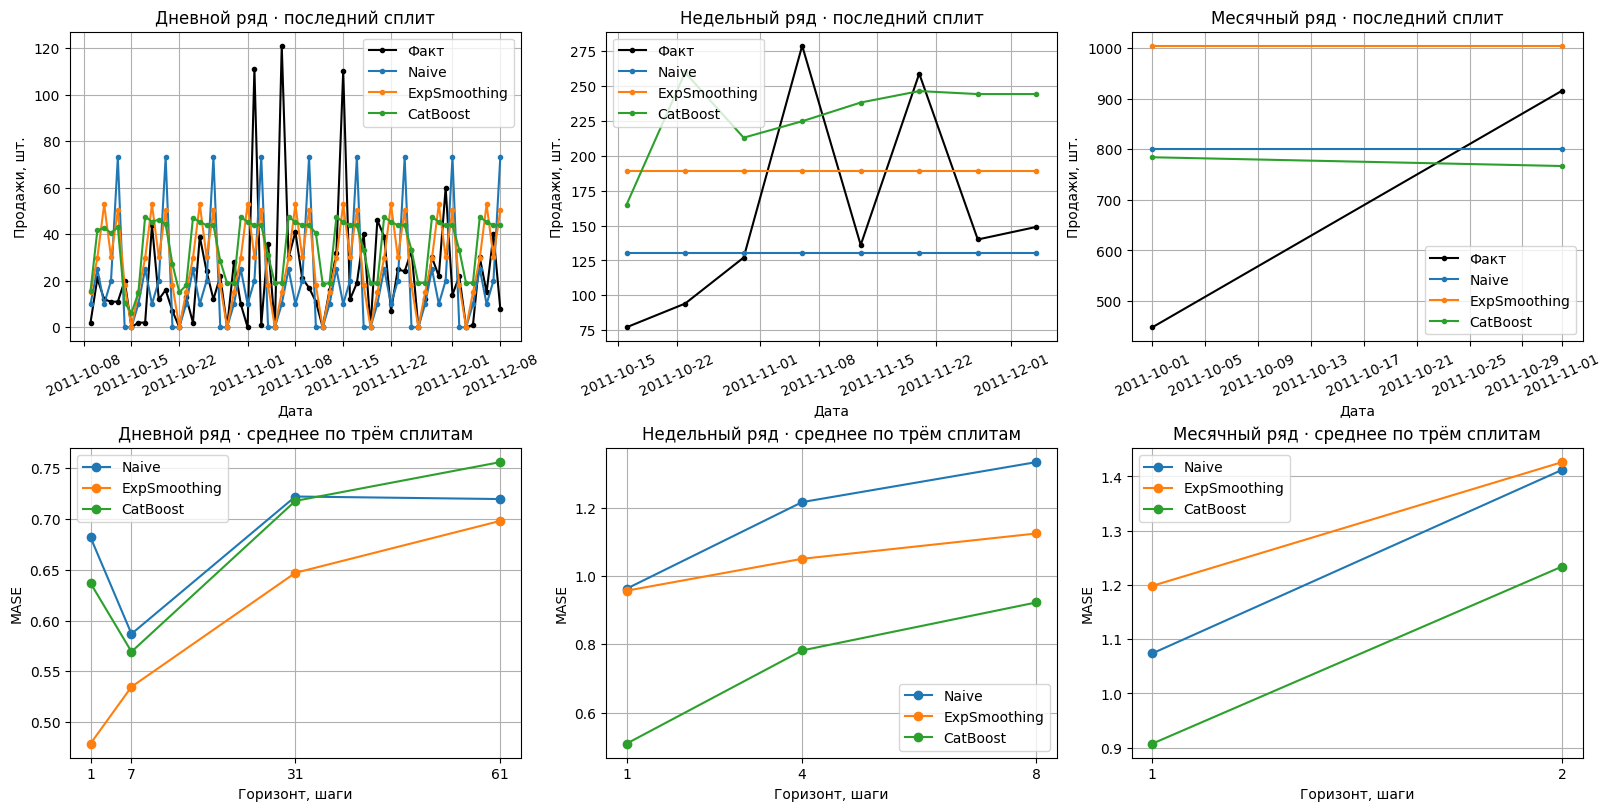

In [11]:
def plot_forecast_comparison(splits, comparison, forecast_functions):
    titles = {
        "daily": "Дневной ряд",
        "weekly": "Недельный ряд",
        "monthly": "Месячный ряд",
    }
    colors = {
        "Naive": "tab:blue",
        "ExpSmoothing": "tab:orange",
        "CatBoost": "tab:green",
    }

    fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout="constrained")

    for col, (frequency, title) in enumerate(titles.items()):
        split = splits[frequency][-1]
        train, test = split["train"], split["test"]

        ax = axes[0, col]
        ax.plot(test.index, test, color="black", marker="o",
                markersize=3, label="Факт")

        for name, forecast_fn in forecast_functions.items():
            prediction = forecast_fn(train, len(test), frequency)
            ax.plot(test.index, prediction, color=colors[name],
                    marker=".", label=name)

        ax.set_title(f"{title} · последний сплит")
        ax.set_xlabel("Дата")
        ax.set_ylabel("Продажи, шт.")
        ax.tick_params(axis="x", labelrotation=25)
        ax.legend()

        ax = axes[1, col]
        mase = comparison.loc[frequency, "MASE"].sort_index()

        for name in forecast_functions:
            ax.plot(mase.index, mase[name], color=colors[name],
                    marker="o", label=name)

        ax.set_title(f"{title} · среднее по трём сплитам")
        ax.set_xticks(mase.index)
        ax.set_xlabel("Горизонт, шаги")
        ax.set_ylabel("MASE")
        ax.legend()

    plt.show()


plot_forecast_comparison(
    splits,
    comparison,
    {
        "Naive": naive_forecast,
        "ExpSmoothing": exp_smoothing_forecast,
        "CatBoost": catboost_forecast,
    },
)

## Выводы

Сравнение на трёх временных сплитах показало, что лучшая модель зависит от частоты. Экспоненциальное сглаживание показало наименьшие MAE и MASE на всех дневных горизонтах. CatBoost лидировал на всех недельных и месячных горизонтах по обеим метрикам.

У CatBoost недельный MAE вырос с 54,09 шт. на горизонте 1 до 98,49 шт. на горизонте 8. На дневном ряду ошибка менялась немонотонно. Метрика на каждом горизонте усредняет ошибки по всей траектории до этого шага, поэтому она зависит и от сложности дат в окне.

При рекурсивном прогнозировании CatBoost использует собственные предсказания в признаках следующих шагов. Это возможная причина ухудшения на длинном дневном горизонте. Месячные результаты предварительны из-за короткой истории и пересечения тестовых окон.